# Part 1.1 – EDA
Overview of structure, distributions and missing data in the Movies dataset.

**Goal:** understand the structure and quality of the data so we know how to clean it before inserting it into MongoDB (Part 1.2), and which fields need care for the Part 2 queries (revenue, vote_average, runtime per decade/genre, cast gender, collections, ratings per user).

In [25]:
# Imports and path to the dataset folder
import ast
import pandas as pd
import matplotlib.pyplot as plt

DATA = "dataset/"

# Parse a Python-literal string (e.g. "[{'id': 16, 'name': 'Animation'}]") into a list/dict; None if missing or invalid
def parse(text):
    try:
        return ast.literal_eval(text) if isinstance(text, str) else None
    except (ValueError, SyntaxError):
        return None

## movies_metadata.csv

In [26]:
# Load movie metadata and show its size and column types
movies = pd.read_csv(DATA + "movies_metadata.csv", low_memory=False)
print(movies.shape)
movies.dtypes

(45466, 24)


adult                        str
belongs_to_collection        str
budget                       str
genres                       str
homepage                     str
id                           str
imdb_id                      str
original_language            str
original_title               str
overview                     str
popularity                   str
poster_path                  str
production_companies         str
production_countries         str
release_date                 str
revenue                  float64
runtime                  float64
spoken_languages             str
status                       str
tagline                      str
title                        str
video                     object
vote_average             float64
vote_count               float64
dtype: object

In [27]:
# Preview the first rows
movies.head(3)

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0


### Malformed rows and duplicates
`id`, `budget` and `popularity` are read as strings, so some rows are shifted/corrupt.

In [28]:
# Rows with a non-numeric id are corrupt (shifted columns), so show them
bad_id = pd.to_numeric(movies["id"], errors="coerce").isna()
print("Non-numeric id:", bad_id.sum())
display(movies.loc[bad_id, ["adult", "budget", "id", "original_language"]])

# Drop the corrupt rows, convert id to int and count duplicate movie ids
movies = movies[~bad_id].copy()
movies["id"] = movies["id"].astype(int)
print("Duplicate ids:", movies["id"].duplicated().sum())

Non-numeric id: 3


,adult,budget,id,original_language
19730,- Written by Ørnås,/ff9qCepilowshEtG2GYWwzt2bs4.jpg,1997-08-20,104.0
29503,Rune Balot goes to a casino connected to the ...,/zV8bHuSL6WXoD6FWogP9j4x80bL.jpg,2012-09-29,68.0
35587,Avalanche Sharks tells the story of a bikini ...,/zaSf5OG7V8X8gqFvly88zDdRm46.jpg,2014-01-01,82.0


Duplicate ids: 30


In [29]:
# The row before each corrupt row is cut off (a line break in overview split the movie in two), so most of its columns are empty
display(movies.loc[movies["title"].isna(), ["id", "title", "release_date", "popularity", "vote_count"]])

# Check whether duplicate ids are identical rows, and if not, which columns differ
print("Exact duplicate rows:", movies.duplicated().sum())
dups = movies[movies["id"].duplicated(keep=False)]
differs = dups.groupby("id").nunique(dropna=False).gt(1)
differs.loc[:, differs.any()].sum().rename("duplicate ids where column differs")

,id,title,release_date,popularity,vote_count
19729,82663,NaN,NaN,NaN,NaN
29502,122662,NaN,NaN,NaN,NaN
35586,249260,NaN,NaN,NaN,NaN


Exact duplicate rows: 17


popularity    13
vote_count     2
Name: duplicate ids where column differs, dtype: int64

### Type conversion

In [30]:
# Convert numeric columns and release_date to proper types (invalid values become NaN/NaT)
for col in ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]:
    movies[col] = pd.to_numeric(movies[col], errors="coerce")
movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
# Summary statistics for the numeric columns
movies[["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]].describe().round(2)

,budget,revenue,runtime,popularity,vote_average,vote_count
count,4.546300e+04,4.546000e+04,45203.00,45460.00,45460.00,45460.00
mean,4.224579e+06,1.120935e+07,94.13,2.92,5.62,109.90
std,1.742413e+07,6.433225e+07,38.41,6.01,1.92,491.31
min,0.000000e+00,0.000000e+00,0.00,0.00,0.00,0.00
25%,0.000000e+00,0.000000e+00,85.00,0.39,5.00,3.00
50%,0.000000e+00,0.000000e+00,95.00,1.13,6.00,10.00
75%,0.000000e+00,0.000000e+00,107.00,3.68,6.80,34.00
max,3.800000e+08,2.787965e+09,1256.00,547.49,10.00,14075.00


### Missing values
Zeros in `budget`, `revenue` and `runtime` mean unknown, so they count as missing too.

In [31]:
# Count missing values (count and %) per column
missing = pd.DataFrame({
    "missing": movies.isna().sum(),
    "missing_%": (movies.isna().mean() * 100).round(1),
})
# Also count zeros in budget/revenue/runtime, since 0 means unknown
for col in ["budget", "revenue", "runtime"]:
    missing.loc[col + " (== 0)", "missing"] = (movies[col] == 0).sum()
    missing.loc[col + " (== 0)", "missing_%"] = round((movies[col] == 0).mean() * 100, 1)
# Show columns with the most missing data first
missing.sort_values("missing_%", ascending=False)

,missing,missing_%
belongs_to_collection,40972,90.1
revenue (== 0),38052,83.7
homepage,37684,82.9
budget (== 0),36573,80.4
tagline,25051,55.1
runtime (== 0),1558,3.4
overview,954,2.1
poster_path,386,0.8
runtime,260,0.6
release_date,87,0.2


In [32]:
# Movies with no votes have a vote_average of 0 that is not a real rating
print("Movies with vote_count == 0:", (movies.vote_count == 0).sum())

Movies with vote_count == 0: 2899


### Distributions

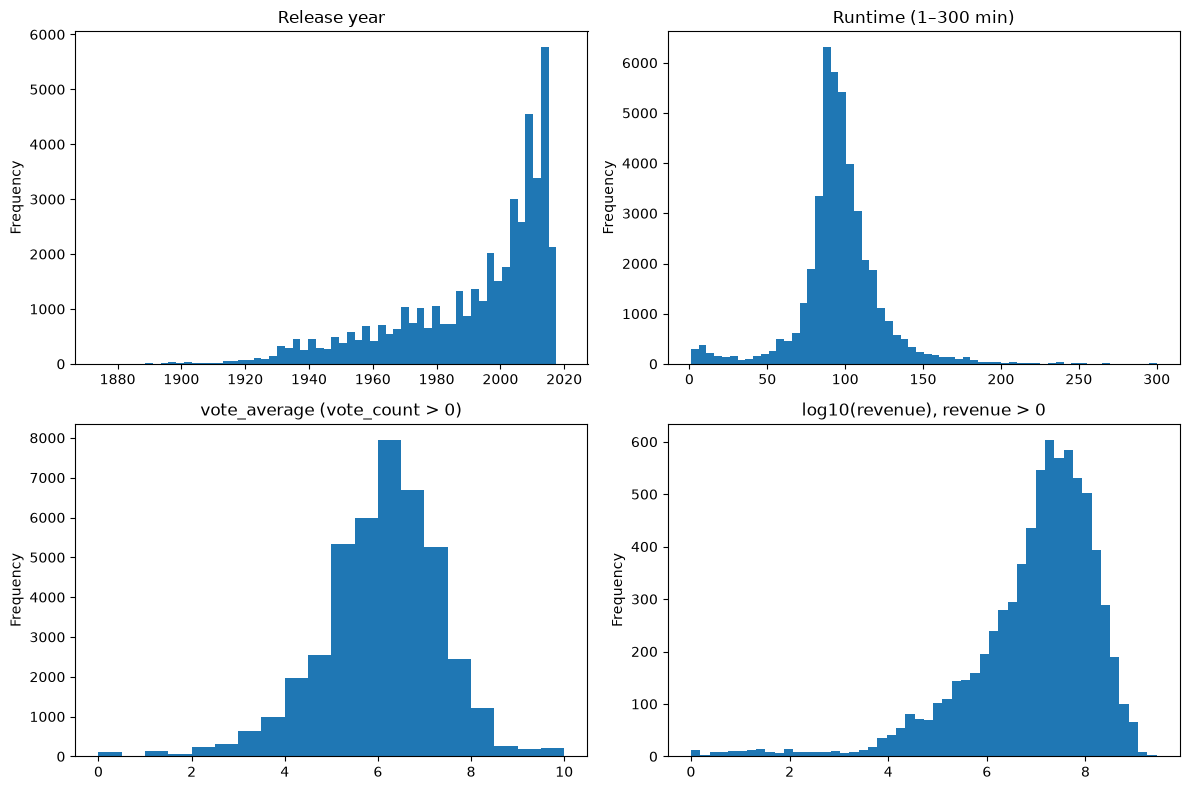

In [33]:
# Histograms of release year, runtime, vote average and log revenue (filtered to remove unknown/extreme values)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
movies["release_date"].dt.year.plot.hist(bins=60, ax=ax[0, 0], title="Release year")
movies.loc[movies.runtime.between(1, 300), "runtime"].plot.hist(bins=60, ax=ax[0, 1], title="Runtime (1–300 min)")
movies.loc[movies.vote_count > 0, "vote_average"].plot.hist(bins=20, ax=ax[1, 0], title="vote_average (vote_count > 0)")
movies.loc[movies.revenue > 0, "revenue"].apply("log10").plot.hist(bins=50, ax=ax[1, 1], title="log10(revenue), revenue > 0")
plt.tight_layout()

### Outliers
Box plots on a log scale (unknown zeros removed), skewness and the number of IQR outliers (above Q3 + 1.5·IQR) for each skewed column.

,skew,IQR outliers
budget,3.1,930
revenue,5.1,838
runtime,6.7,2181
vote_count,10.1,6464


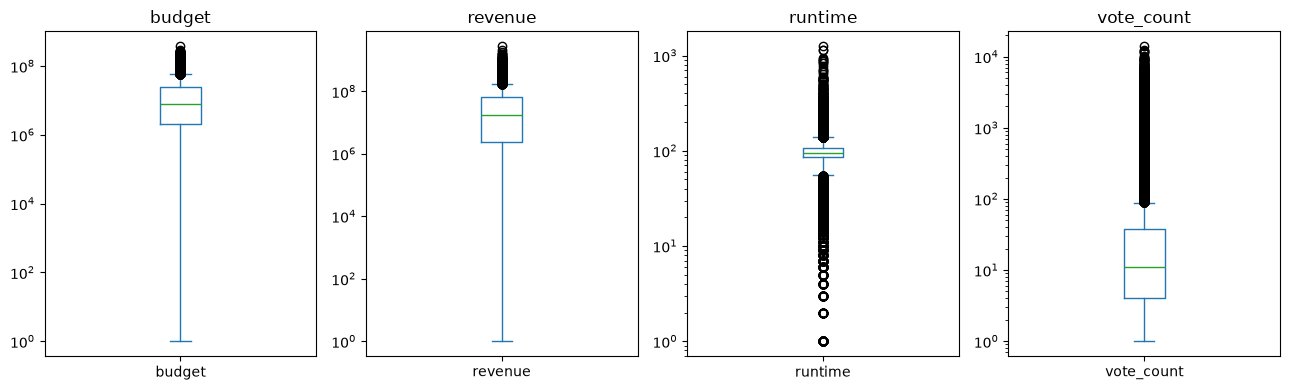

In [34]:
# Box plots of the skewed numeric columns, ignoring zeros (unknown)
skewed = ["budget", "revenue", "runtime", "vote_count"]
fig, ax = plt.subplots(1, len(skewed), figsize=(13, 4))
for axis, col in zip(ax, skewed):
    movies.loc[movies[col] > 0, col].plot.box(ax=axis, logy=True, title=col)
plt.tight_layout()

# Count values above Q3 + 1.5 * IQR
def iqr_outliers(values):
    q1, q3 = values.quantile([0.25, 0.75])
    return (values > q3 + 1.5 * (q3 - q1)).sum()

pd.DataFrame({
    "skew": [movies.loc[movies[col] > 0, col].skew() for col in skewed],
    "IQR outliers": [iqr_outliers(movies.loc[movies[col] > 0, col]) for col in skewed],
}, index=skewed).round(1)

In [35]:
# Longest runtimes: check whether they are errors or real (e.g. TV mini-series)
print("Runtime > 300 min:", (movies.runtime > 300).sum())
display(movies.nlargest(5, "runtime")[["title", "runtime", "release_date"]])

# Movies with known budget and revenue, and how English-heavy that subset is
known_money = (movies.budget > 0) & (movies.revenue > 0)
print("Movies with both budget and revenue > 0:", known_money.sum())
print(f"English-language share: all movies {(movies.original_language == 'en').mean():.0%}"
      f" | movies with budget and revenue {(movies.loc[known_money, 'original_language'] == 'en').mean():.0%}")

Runtime > 300 min: 108


,title,runtime,release_date
24178,Centennial,1256.0,1978-10-01
19965,Jazz,1140.0,2001-01-09
40938,Baseball,1140.0,1994-09-18
13767,Berlin Alexanderplatz,931.0,1980-08-28
13953,Heimat: A Chronicle of Germany,925.0,1984-09-16


Movies with both budget and revenue > 0: 5381
English-language share: all movies 71% | movies with budget and revenue 89%


### Nested fields

In [36]:
# Parse the nested columns from strings into Python lists/dicts
nested = ["genres", "production_companies", "production_countries", "spoken_languages", "belongs_to_collection"]
for col in nested:
    movies[col] = movies[col].apply(parse)

# Count null vs. empty-list values for each nested column
pd.DataFrame({
    "null": [movies[col].isna().sum() for col in nested],
    "empty": [movies[col].apply(lambda value: isinstance(value, list) and len(value) == 0).sum() for col in nested],
}, index=nested)

,null,empty
genres,0,2442
production_companies,3,11875
production_countries,3,6282
spoken_languages,3,3829
belongs_to_collection,40972,0


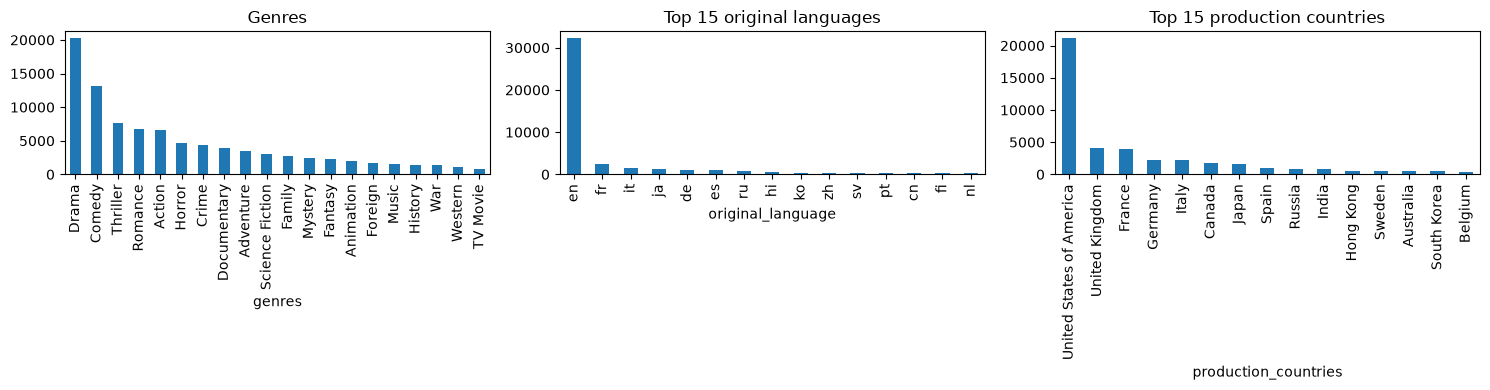

In [37]:
# Bar charts of the most common genres, original languages and production countries
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
movies["genres"].explode().dropna().str["name"].value_counts().plot.bar(ax=ax[0], title="Genres")
movies["original_language"].value_counts().head(15).plot.bar(ax=ax[1], title="Top 15 original languages")
movies["production_countries"].explode().dropna().str["name"].value_counts().head(15).plot.bar(ax=ax[2], title="Top 15 production countries")
plt.tight_layout()

In [38]:
# Number of movies that belong to a collection, and the largest collections
print("Movies in a collection:", movies["belongs_to_collection"].notna().sum())
movies["belongs_to_collection"].dropna().str["name"].value_counts().head(10)

Movies in a collection: 4491


belongs_to_collection
The Bowery Boys                           29
Totò Collection                           27
James Bond Collection                     26
Zatôichi: The Blind Swordsman             26
The Carry On Collection                   25
Pokémon Collection                        22
Charlie Chan (Sidney Toler) Collection    21
Godzilla (Showa) Collection               16
Uuno Turhapuro                            15
Charlie Chan (Warner Oland) Collection    15
Name: count, dtype: int64

### Relationships
How vote_average depends on vote_count, how revenue relates to budget, and how genres and runtime change over time.

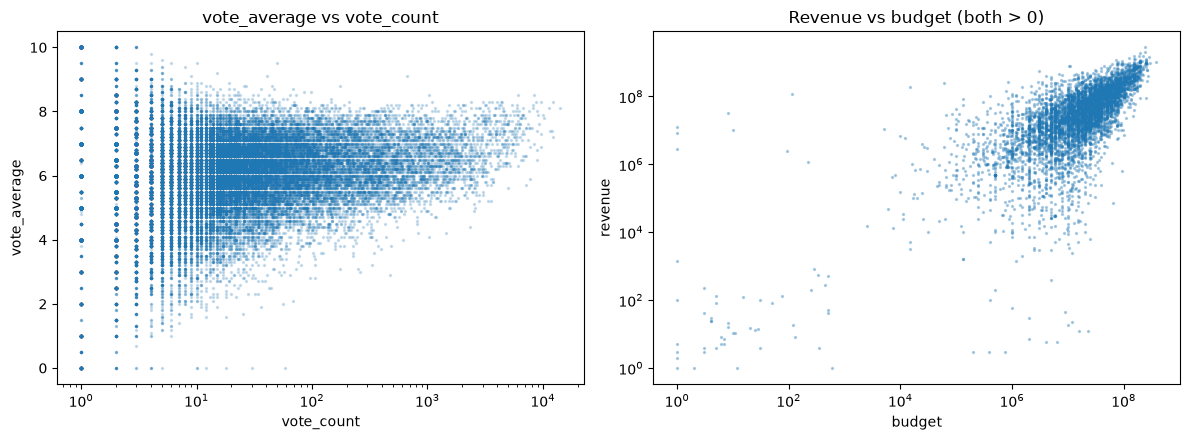

In [39]:
# Scatter plots: vote_average vs vote_count, and revenue vs budget (log scales, unknown zeros removed)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
movies[movies.vote_count > 0].plot.scatter(x="vote_count", y="vote_average", logx=True, s=2, alpha=0.2, ax=ax[0], title="vote_average vs vote_count")
movies[(movies.budget > 0) & (movies.revenue > 0)].plot.scatter(x="budget", y="revenue", loglog=True, s=2, alpha=0.3, ax=ax[1], title="Revenue vs budget (both > 0)")
plt.tight_layout()

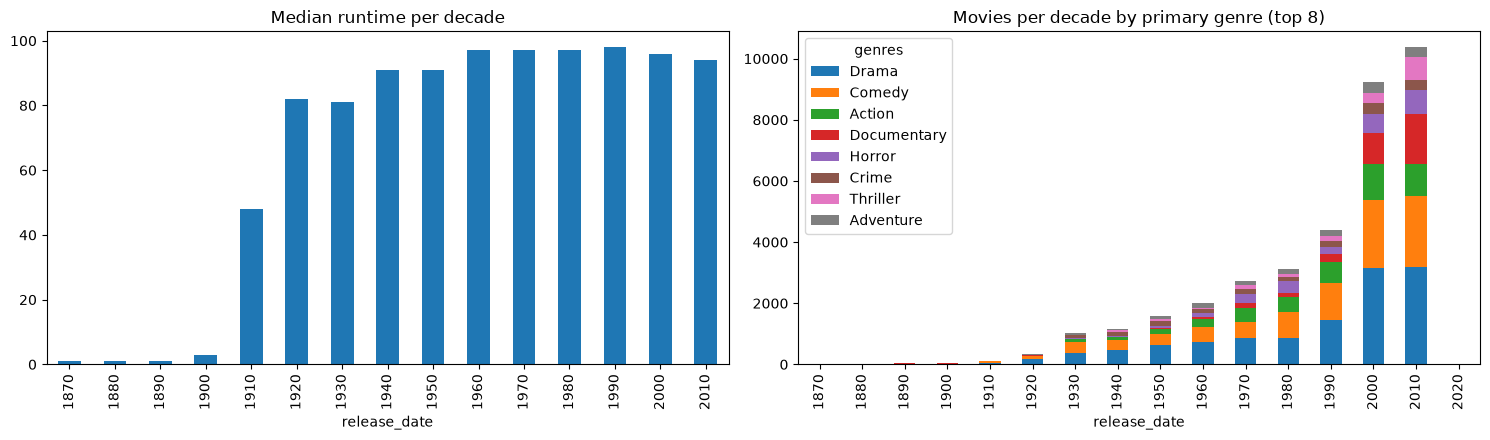

In [40]:
# Decade and primary genre (first element in genres), as used in Part 2 question 5
decade = (movies["release_date"].dt.year // 10 * 10).astype("Int64")
primary_genre = movies["genres"].str[0].str["name"]

# Median runtime per decade (ignoring unknown and extreme runtimes) and movie count per decade and primary genre
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
movies.loc[movies.runtime.between(1, 300), "runtime"].groupby(decade).median().plot.bar(ax=ax[0], title="Median runtime per decade")
top_genres = primary_genre.value_counts().head(8).index
pd.crosstab(decade, primary_genre)[top_genres].plot.bar(stacked=True, ax=ax[1], title="Movies per decade by primary genre (top 8)")
plt.tight_layout()

## credits.csv

In [41]:
# Load credits, check duplicate ids and whether duplicate rows differ in cast or crew
credits = pd.read_csv(DATA + "credits.csv")
dup = credits[credits["id"].duplicated(keep=False)].groupby("id").nunique()
print(credits.shape, "| duplicate ids:", credits["id"].duplicated().sum(),
      "| where cast differs:", (dup["cast"] > 1).sum(), "| where crew differs:", (dup["crew"] > 1).sum())
# Parse the cast/crew lists
credits["cast"] = credits["cast"].apply(parse)
credits["crew"] = credits["crew"].apply(parse)
# Check empty cast/crew lists, ids missing from movies, and movies without a director
print("Empty cast:", (credits["cast"].str.len() == 0).sum(), "| empty crew:", (credits["crew"].str.len() == 0).sum())
print("Ids not in movies:", (~credits["id"].isin(movies["id"])).sum())
print("Movies without director:", (~credits["crew"].apply(lambda crew_list: any(person["job"] == "Director" for person in crew_list))).sum())

(45476, 3) | duplicate ids: 44 | where cast differs: 0 | where crew differs: 7
Empty cast: 2418 | empty crew: 771
Ids not in movies: 0
Movies without director: 887


In [42]:
# Flatten cast and crew so each row is one person in one movie
cast = credits["cast"].explode().dropna()
crew = credits["crew"].explode().dropna()
print("Cast entries:", len(cast), "| crew entries:", len(crew))
# Share of each cast gender and the most common crew jobs
print("Cast gender (0 = unknown, 1 = female, 2 = male):")
print(cast.str["gender"].value_counts(normalize=True).round(3))
crew.str["job"].value_counts().head(10)

Cast entries: 562474 | crew entries: 464314
Cast gender (0 = unknown, 1 = female, 2 = male):
cast
2    0.403
0    0.398
1    0.199
Name: proportion, dtype: float64


crew
Director                   49048
Producer                   43555
Writer                     30431
Screenplay                 25163
Editor                     23800
Director of Photography    20659
Executive Producer         18866
Original Music Composer    15790
Casting                    12635
Art Direction              11689
Name: count, dtype: int64

In [43]:
# An actor listed more than once in the same movie would be counted twice in questions 2, 3, 6 and 8 in part 2
def has_repeats(people):
    ids = [person["id"] for person in people]
    return len(ids) != len(set(ids))

unique_credits = credits.drop_duplicates("id")
print("Movies listing the same actor more than once:", unique_credits["cast"].apply(has_repeats).sum())
print("Movies with the same actor twice among the top 5 billed:", unique_credits["cast"].apply(lambda cast_list: has_repeats(sorted(cast_list, key=lambda person: person["order"])[:5])).sum())
print("Movies listing the same director more than once:", unique_credits["crew"].apply(lambda crew_list: has_repeats([person for person in crew_list if person["job"] == "Director"])).sum())

# Every repeated entry is a separate credit with its own credit_id, not a copied row
cast_rows = pd.DataFrame([{"movie_id": movie_id, **person} for movie_id, cast_list in zip(unique_credits["id"], unique_credits["cast"]) for person in cast_list])
repeated = cast_rows[cast_rows.duplicated(["movie_id", "id"], keep=False)]
print("Repeated cast entries:", len(repeated), "| sharing a credit_id:", repeated["credit_id"].duplicated().sum())

# Examples: the same role credited twice (The Godfather Part II, 240) and one actor in two roles (Beauty and the Beast, 10020)
repeated[repeated["movie_id"].isin([240, 10020])][["movie_id", "name", "character", "order"]]

Movies listing the same actor more than once: 951
Movies with the same actor twice among the top 5 billed: 151
Movies listing the same director more than once: 0
Repeated cast entries: 2363 | sharing a credit_id: 0


,movie_id,name,character,order
9998,10020,David Ogden Stiers,Cogsworth (voice),4
10014,10020,David Ogden Stiers,Narrator (voice),20
20749,240,Roman Coppola,Sonny Corleone as a Boy,41
20791,240,Roman Coppola,Sonny Corleone as a Boy (uncredited),83


## keywords.csv

In [44]:
# Load keywords, check duplicate ids (and whether duplicate rows differ), then parse and count empty keyword lists
keywords = pd.read_csv(DATA + "keywords.csv")
dup = keywords[keywords["id"].duplicated(keep=False)].groupby("id").nunique()
print(keywords.shape, "| duplicate ids:", keywords["id"].duplicated().sum(), "| where keywords differ:", (dup["keywords"] > 1).sum())
keywords["keywords"] = keywords["keywords"].apply(parse)
print("Empty keyword lists:", (keywords["keywords"].str.len() == 0).sum())

(46419, 2) | duplicate ids: 987 | where keywords differ: 0
Empty keyword lists: 14795


## ratings.csv and links.csv

In [45]:
# Load ratings (compact dtypes to save memory) and the MovieLens -> TMDB links
ratings = pd.read_csv(DATA + "ratings.csv", dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"})
links = pd.read_csv(DATA + "links.csv")
# Basic stats: size, unique users/movies, missing values, duplicates and time range
print(ratings.shape, "| users:", ratings.userId.nunique(), "| movies:", ratings.movieId.nunique())
print("Missing values:", ratings.isna().sum().sum(), "| duplicate (user, movie):", ratings.duplicated(["userId", "movieId"]).sum())
print("Timestamp range:", pd.to_datetime(ratings.timestamp.min(), unit="s"), "-->", pd.to_datetime(ratings.timestamp.max(), unit="s"))
print("links missing tmdbId:", links.tmdbId.isna().sum())

(26024289, 4) | users: 270896 | movies: 45115
Missing values: 0 | duplicate (user, movie): 0
Timestamp range: 1995-01-09 11:46:44 --> 2017-08-04 06:57:50
links missing tmdbId: 219


Users with >= 20 ratings: 166444
Ratings per movie: {'count': 45115.0, 'mean': 576.8, 'std': 3037.4, 'min': 1.0, '25%': 2.0, '50%': 8.0, '75%': 69.0, 'max': 91921.0}


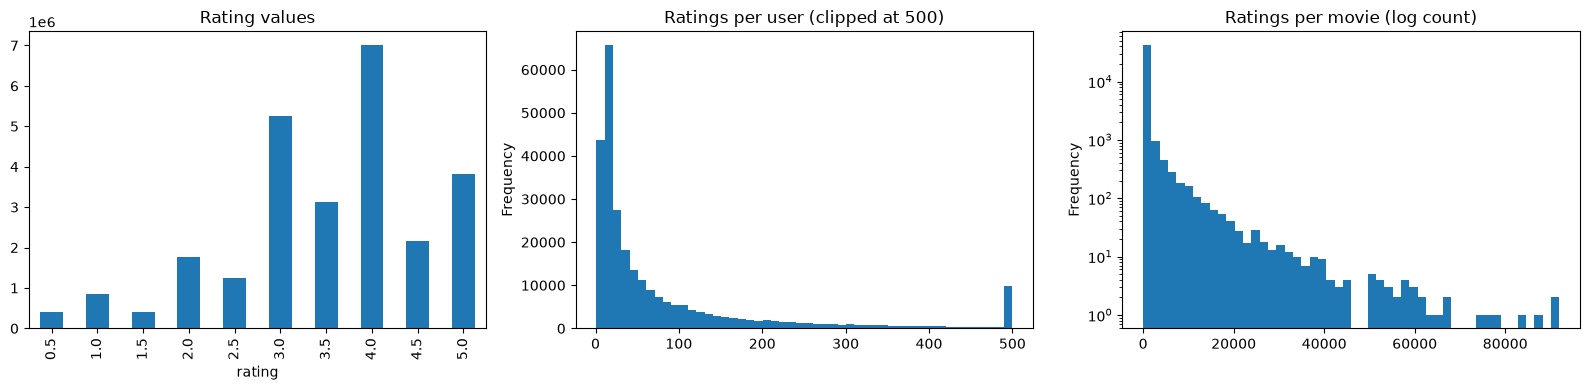

In [46]:
# Distribution of rating values, number of ratings per user and number of ratings per movie
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ratings["rating"].value_counts().sort_index().plot.bar(ax=ax[0], title="Rating values")
ratings.groupby("userId").size().clip(upper=500).plot.hist(bins=50, ax=ax[1], title="Ratings per user (clipped at 500)")
ratings.groupby("movieId").size().plot.hist(bins=50, logy=True, ax=ax[2], title="Ratings per movie (log count)")
plt.tight_layout()
print("Users with >= 20 ratings:", (ratings.groupby("userId").size() >= 20).sum())
print("Ratings per movie:", ratings.groupby("movieId").size().describe().round(1).to_dict())

In [47]:
# Map each rating's MovieLens movieId to a TMDB id and count ratings that cannot be matched to a movie
tmdb = ratings["movieId"].map(links.set_index("movieId")["tmdbId"])
print("Ratings without tmdbId:", tmdb.isna().sum())
print("Ratings whose movie is not in metadata:", (~tmdb.isin(movies["id"])).sum())

# Some TMDB ids have several MovieLens ids, so a user can end up with two ratings for the same TMDB movie
print("TMDB ids with more than one MovieLens id:", links["tmdbId"].dropna().duplicated().sum())
matched = ratings.assign(tmdb=tmdb)[tmdb.isin(movies["id"])]
print("Duplicate (user, TMDB id) ratings:", matched.duplicated(["userId", "tmdb"]).sum())

Ratings without tmdbId: 13503
Ratings whose movie is not in metadata: 42707
TMDB ids with more than one MovieLens id: 30
Duplicate (user, TMDB id) ratings: 125


## Findings
- **Corrupt rows:** 3 rows have shifted columns (non-numeric `id`), and the row before each is truncated (no `title`, `popularity` or votes). All 6 are dropped.
- **Duplicates:** the 30 duplicate metadata ids differ only in `popularity` and `vote_count`, so we keep the row with the most votes. Duplicate credits rows (44) differ only in crew and duplicate keyword rows (987) are identical, so we keep the first row.
- **Unknown values:** `budget` = 0 (80%), `revenue` = 0 (84%) and `runtime` = 0 (3%) mean unknown, and 2,899 movies with `vote_count` = 0 have a fake `vote_average` of 0. These must be left out so they do not pull down medians and means in questions 1, 4, 5 and 8 in part 2. Revenue results therefore cover only a small subset of movies.
- **Outliers:** budget, revenue, runtime and vote_count are strongly right-skewed, but the extreme values are real (e.g. runtimes up to 1,256 min are mini-series), so they are kept.
- **Sparse fields:** only 4,491 movies belong to a collection (question 4 in part 2), and `tagline` is missing for 55%, so the text search in question 7 in part 2 relies mostly on `overview`. 87 movies have no `release_date` and cannot be placed in a decade (questions 5 and 6 in part 2).
- **Nested fields** are Python-literal strings that must be parsed. 2,442 movies have no genres, so they have no primary genre (question 5 in part 2).
- **Credits:** 2,418 movies have no cast and 887 have no director. 40% of cast have unknown gender, which must be ignored in question 6 in part 2. 951 movies list the same actor more than once. These are not copied rows, since every entry is a separate credit with its own `credit_id`. Some are the same role credited twice (e.g. with and without "(uncredited)"), but many are one actor playing several roles (e.g. David Ogden Stiers as both Cogsworth and the Narrator in Beauty and the Beast). The entries are therefore kept as one cast entry per role, and Part 2 must count each actor once per movie in questions 2, 3 and 8. In question 6, 151 movies have the same actor twice among the top 5 billed, so the top 5 should be taken over distinct actors. No movie lists the same director twice.
- **Ratings:** 26M ratings from 270,896 users, up to 91,921 for one movie, so they are too many to embed in movies. 166,444 users have at least 20 ratings (question 10 in part 2). Ratings link to movies via `links.csv`. 42,707 ratings cannot be matched to a movie and are dropped. Some TMDB ids have two MovieLens ids, which gives 125 cases where a user rated the same movie twice.